# Advanced Topics
### Data Science Core Concepts 101 — by Yunhan Jin

This notebook covers topics that bridge foundational DS and real-world practice:
- Probability foundations underlying ML
- Regularization (L1/L2/ElasticNet)
- Gradient boosting
- Production pitfalls

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Recreate housing dataset
np.random.seed(42)
n = 500
neighborhoods = ['Downtown', 'Midtown', 'Uptown', 'Suburbs', 'Riverside'] * (n // 5)

df = pd.DataFrame({
    'sqft':         np.random.normal(1800, 400, n).astype(int).clip(600, 4000),
    'bedrooms':     np.random.choice([2, 3, 4, 5], n, p=[0.2, 0.4, 0.3, 0.1]),
    'neighborhood': neighborhoods,
    'condition':    np.random.choice(['Poor','Fair','Good','Excellent'], n, p=[0.1,0.2,0.5,0.2]),
    'year_built':   np.random.randint(1960, 2020, n),
    'has_garage':   np.random.choice([True, False], n, p=[0.7, 0.3]),
    'listing_date': pd.date_range('2020-01-01', periods=n, freq='D'),
})

hood_price = {'Downtown': 1.3, 'Midtown': 1.1, 'Uptown': 1.0, 'Suburbs': 0.9, 'Riverside': 1.05}
cond_price  = {'Poor': 0, 'Fair': 1, 'Good': 2, 'Excellent': 3}

df['price'] = (
    80000 + df['sqft'] * 120 + df['bedrooms'] * 8000
    + df['condition'].map(cond_price) * 15000
    + df['has_garage'].astype(int) * 12000
    + np.random.normal(0, 20000, n)
) * df['neighborhood'].map(hood_price)
df['price'] = df['price'].clip(100000, 1000000).astype(int)

df['condition_encoded'] = df['condition'].map({'Poor': 0, 'Fair': 1, 'Good': 2, 'Excellent': 3})
df = pd.get_dummies(df, columns=['neighborhood'], drop_first=True)
df['has_garage']    = df['has_garage'].astype(int)
df['house_age']     = 2024 - df['year_built']
df['listing_month'] = df['listing_date'].dt.month
df['is_summer']     = df['listing_month'].isin([6, 7, 8]).astype(int)
df['log_price']     = np.log(df['price'])
df['high_value']    = (df['price'] > df['price'].median()).astype(int)

feature_cols = [
    'sqft', 'bedrooms', 'condition_encoded', 'has_garage', 'house_age', 'is_summer',
    'neighborhood_Midtown', 'neighborhood_Riverside', 'neighborhood_Suburbs', 'neighborhood_Uptown'
]
X = df[feature_cols]
y_reg = df['log_price']
y_clf = df['high_value']

X_train, X_test, y_reg_train, y_reg_test = train_test_split(X, y_reg, test_size=0.2, random_state=42)
_, _,           y_clf_train, y_clf_test  = train_test_split(X, y_clf, test_size=0.2, random_state=42)

# Scale for regularized models
scaler   = StandardScaler()
X_tr_sc  = scaler.fit_transform(X_train)
X_te_sc  = scaler.transform(X_test)
X_all_sc = scaler.fit_transform(X)

print('Setup complete.')

Setup complete.


---
## Section 1: Probability Foundations
Probability is the language of uncertainty — and ML is fundamentally about quantifying uncertainty. Three distributions you'll encounter constantly:

| Distribution | Use case | Parameters |
|---|---|---|
| Normal | Continuous values, residuals, features after CLT | μ (mean), σ (std) |
| Binomial | Count of successes in n trials (conversion, clicks) | n (trials), p (success prob) |
| Poisson | Count of events in a fixed interval (arrivals, errors) | λ (rate) |

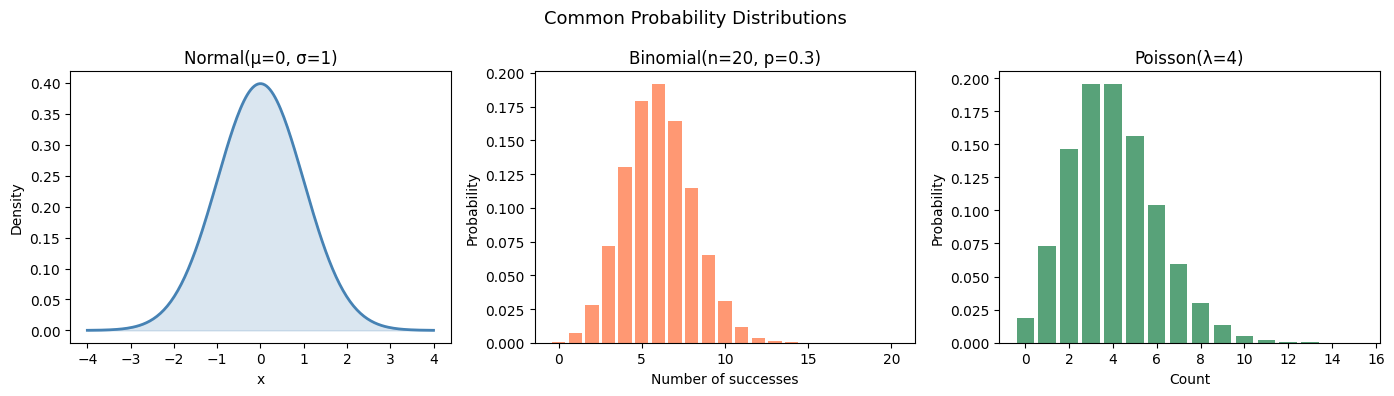

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Normal
x = np.linspace(-4, 4, 200)
axes[0].plot(x, stats.norm.pdf(x, 0, 1), color='steelblue', lw=2)
axes[0].fill_between(x, stats.norm.pdf(x, 0, 1), alpha=0.2, color='steelblue')
axes[0].set_title('Normal(μ=0, σ=1)')
axes[0].set_xlabel('x')
axes[0].set_ylabel('Density')

# Binomial
k = np.arange(0, 21)
axes[1].bar(k, stats.binom.pmf(k, n=20, p=0.3), color='coral', alpha=0.8)
axes[1].set_title('Binomial(n=20, p=0.3)')
axes[1].set_xlabel('Number of successes')
axes[1].set_ylabel('Probability')

# Poisson
k_pois = np.arange(0, 16)
axes[2].bar(k_pois, stats.poisson.pmf(k_pois, mu=4), color='seagreen', alpha=0.8)
axes[2].set_title('Poisson(λ=4)')
axes[2].set_xlabel('Count')
axes[2].set_ylabel('Probability')

plt.suptitle('Common Probability Distributions', fontsize=13)
plt.tight_layout()
plt.show()

### 1.1 Central Limit Theorem (CLT)
The **CLT** states: the distribution of sample means approaches a normal distribution as sample size grows, regardless of the original distribution. This is why we can apply z-tests and t-tests broadly.

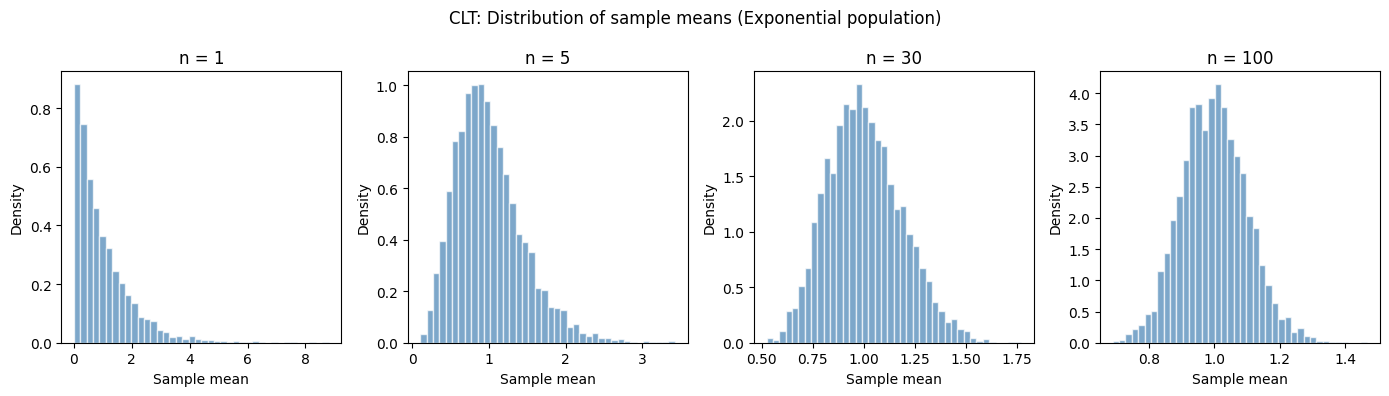

In [3]:
# Demonstrate CLT on a skewed distribution (exponential)
n_simulations = 5000
sample_sizes  = [1, 5, 30, 100]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, size in zip(axes, sample_sizes):
    sample_means = [np.random.exponential(scale=1, size=size).mean() for _ in range(n_simulations)]
    ax.hist(sample_means, bins=40, color='steelblue', alpha=0.7, edgecolor='white', density=True)
    ax.set_title(f'n = {size}')
    ax.set_xlabel('Sample mean')
    ax.set_ylabel('Density')

plt.suptitle('CLT: Distribution of sample means (Exponential population)', fontsize=12)
plt.tight_layout()
plt.show()

### 1.2 Bayes' Theorem
$$P(A|B) = \frac{P(B|A) \cdot P(A)}{P(B)}$$

**Posterior** = (likelihood × prior) / evidence

Example: a medical test for a rare disease (1% prevalence) has 99% sensitivity and 95% specificity. If a patient tests positive, what is the probability they actually have the disease?

In [4]:
p_disease     = 0.01   # prior: 1% prevalence
p_pos_given_D = 0.99   # sensitivity (true positive rate)
p_pos_given_H = 0.05   # 1 - specificity (false positive rate)

# P(positive) = P(pos|disease) * P(disease) + P(pos|healthy) * P(healthy)
p_positive = p_pos_given_D * p_disease + p_pos_given_H * (1 - p_disease)

# P(disease | positive) via Bayes
p_disease_given_pos = (p_pos_given_D * p_disease) / p_positive

print('Bayes\' Theorem — Disease Testing')
print(f'  Prevalence (prior):    {p_disease:.0%}')
print(f'  Sensitivity (TPR):     {p_pos_given_D:.0%}')
print(f'  False positive rate:   {p_pos_given_H:.0%}')
print()
print(f'  P(positive):           {p_positive:.4f}')
print(f'  P(disease | positive): {p_disease_given_pos:.4f}  ← posterior')
print()
print('Intuition: even with a 99% accurate test, a positive result only means')
print(f'a {p_disease_given_pos:.0%} chance of disease when prevalence is just {p_disease:.0%}.')

Bayes' Theorem — Disease Testing
  Prevalence (prior):    1%
  Sensitivity (TPR):     99%
  False positive rate:   5%

  P(positive):           0.0594
  P(disease | positive): 0.1667  ← posterior

Intuition: even with a 99% accurate test, a positive result only means
a 17% chance of disease when prevalence is just 1%.


---
## Section 2: Regularization — L1, L2, ElasticNet

Regularization adds a penalty to the loss function to prevent overfitting by discouraging large coefficients.

| Method | Penalty | Effect |
|--------|---------|--------|
| Ridge (L2) | α × Σwᵢ² | Shrinks all coefficients toward zero, keeps all features |
| Lasso (L1) | α × Σ|wᵢ| | Drives some coefficients exactly to zero — automatic feature selection |
| ElasticNet | mix of L1 + L2 | Combines both — sparse but stable under correlated features |

Key difference: **Lasso produces sparse models** (zero out irrelevant features). Ridge keeps all features but shrinks them.

In [5]:
models = {
    'Ridge':      Ridge(alpha=1.0),
    'Lasso':      Lasso(alpha=0.01),
    'ElasticNet': ElasticNet(alpha=0.01, l1_ratio=0.5),
}

coef_data = {}
for name, model in models.items():
    model.fit(X_tr_sc, y_reg_train)
    coef_data[name] = model.coef_
    r2 = model.score(X_te_sc, y_reg_test)
    n_nonzero = np.sum(model.coef_ != 0)
    print(f'{name:12s} | Test R²: {r2:.4f} | Non-zero coefficients: {n_nonzero}/{len(feature_cols)}')

coef_df = pd.DataFrame(coef_data, index=feature_cols)
print()
print('Coefficients:')
print(coef_df.round(4))

Ridge        | Test R²: 0.9011 | Non-zero coefficients: 10/10
Lasso        | Test R²: 0.8407 | Non-zero coefficients: 8/10
ElasticNet   | Test R²: 0.8836 | Non-zero coefficients: 8/10

Coefficients:
                         Ridge   Lasso  ElasticNet
sqft                    0.1277  0.1182      0.1225
bedrooms                0.0242  0.0121      0.0180
condition_encoded       0.0382  0.0258      0.0319
has_garage              0.0170  0.0088      0.0128
house_age              -0.0030 -0.0000     -0.0000
is_summer               0.0018  0.0000      0.0000
neighborhood_Midtown   -0.0621 -0.0214     -0.0408
neighborhood_Riverside -0.0835 -0.0419     -0.0617
neighborhood_Suburbs   -0.1425 -0.1016     -0.1208
neighborhood_Uptown    -0.1025 -0.0617     -0.0810


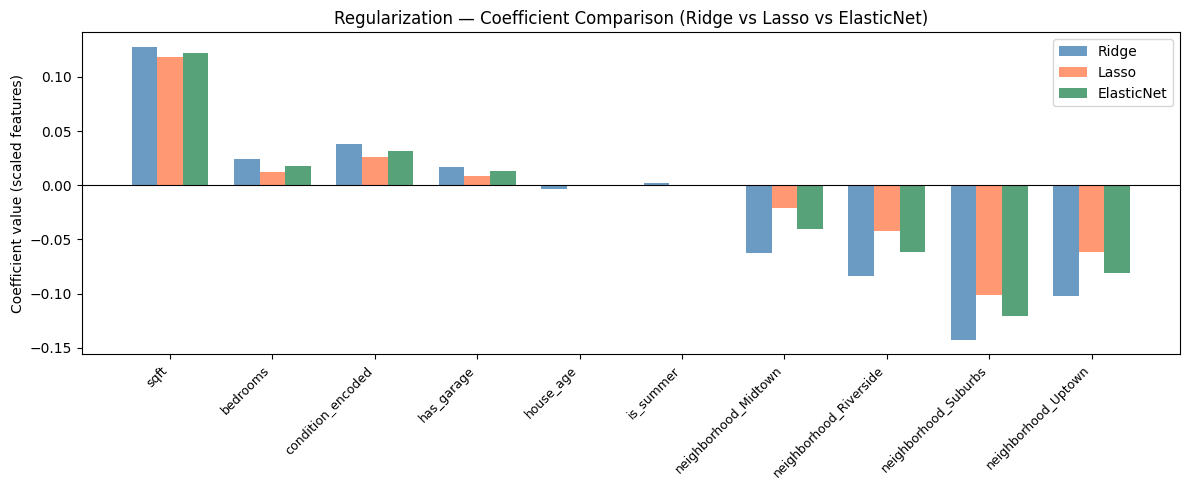

In [6]:
# Visualize coefficient comparison
x_pos = np.arange(len(feature_cols))
width = 0.25
colors = ['steelblue', 'coral', 'seagreen']

fig, ax = plt.subplots(figsize=(12, 5))
for i, (name, color) in enumerate(zip(models.keys(), colors)):
    ax.bar(x_pos + i * width, coef_df[name], width, label=name, color=color, alpha=0.8)

ax.set_xticks(x_pos + width)
ax.set_xticklabels(feature_cols, rotation=45, ha='right', fontsize=9)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Coefficient value (scaled features)')
ax.set_title('Regularization — Coefficient Comparison (Ridge vs Lasso vs ElasticNet)')
ax.legend()
plt.tight_layout()
plt.show()

---
## Section 3: Gradient Boosting

**Gradient Boosting** builds trees **sequentially** — each tree corrects the errors of the previous one by fitting the residuals (negative gradients of the loss). Contrast with Random Forest, which builds trees **independently in parallel** and averages.

| | Random Forest | Gradient Boosting |
|--|---------------|-------------------|
| Training | Parallel, independent trees | Sequential, each corrects the last |
| Strengths | Fast, less tuning, robust | Higher accuracy on tabular data |
| Weaknesses | Less accurate peak performance | Slower to train, more hyperparameters |
| Overfitting | Resistant | More prone — needs `n_estimators` + `learning_rate` tuned together |

XGBoost, LightGBM, and CatBoost are industry-standard implementations of gradient boosting.

In [7]:
rf  = RandomForestClassifier(n_estimators=100, random_state=42)
gbm = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)

rf.fit(X_train, y_clf_train)
gbm.fit(X_train, y_clf_train)

rf_cv  = cross_val_score(rf,  X, y_clf, cv=5, scoring='accuracy')
gbm_cv = cross_val_score(gbm, X, y_clf, cv=5, scoring='accuracy')

print('Random Forest        | Train: {:.4f} | Test: {:.4f} | 5-Fold CV: {:.4f} ± {:.4f}'.format(
    rf.score(X_train, y_clf_train), rf.score(X_test, y_clf_test), rf_cv.mean(), rf_cv.std()))
print('Gradient Boosting    | Train: {:.4f} | Test: {:.4f} | 5-Fold CV: {:.4f} ± {:.4f}'.format(
    gbm.score(X_train, y_clf_train), gbm.score(X_test, y_clf_test), gbm_cv.mean(), gbm_cv.std()))

Random Forest        | Train: 1.0000 | Test: 0.8500 | 5-Fold CV: 0.8580 ± 0.0194
Gradient Boosting    | Train: 0.9700 | Test: 0.9000 | 5-Fold CV: 0.8580 ± 0.0279


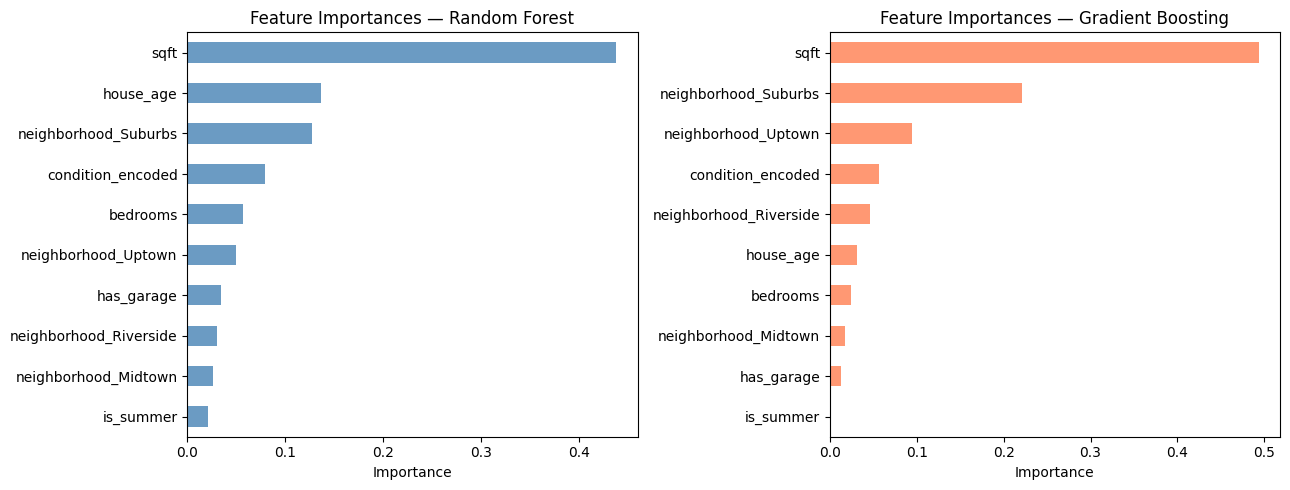

In [8]:
# Feature importance comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, model, title, color in zip(
    axes,
    [rf, gbm],
    ['Random Forest', 'Gradient Boosting'],
    ['steelblue', 'coral']
):
    imp = pd.Series(model.feature_importances_, index=feature_cols).sort_values()
    imp.plot(kind='barh', ax=ax, color=color, alpha=0.8)
    ax.set_title(f'Feature Importances — {title}')
    ax.set_xlabel('Importance')

plt.tight_layout()
plt.show()

---
## Section 4: Production Pitfalls

Models that perform well in notebooks often fail in production. Two of the most common causes:

### 4.1 Train-Serve Skew
**Train-serve skew** occurs when the data at prediction time looks different from training data. A classic example: fitting a scaler or encoder on the full dataset (including test), then using it in production.

**Rule**: fit ALL preprocessing on train only. Transform train and test/production with that fitted object.

In [9]:
# WRONG: scaler sees test data during fit — data leakage
scaler_wrong = StandardScaler()
X_all_wrong  = scaler_wrong.fit_transform(X)   # fit on ALL data including test

# CORRECT: scaler fitted only on train, transforms both
scaler_right    = StandardScaler()
X_train_right   = scaler_right.fit_transform(X_train)  # fit on train only
X_test_right    = scaler_right.transform(X_test)        # transform test with train stats

print('Scaler fitted on train only (correct):')
print(f'  Train mean used: {scaler_right.mean_[:3].round(2)}')
print()
print('In production, always load the SAME fitted scaler object and call .transform().')
print('Never refit the scaler on new incoming data.')

Scaler fitted on train only (correct):
  Train mean used: [1.80072e+03 3.30000e+00 1.76000e+00]

In production, always load the SAME fitted scaler object and call .transform().
Never refit the scaler on new incoming data.


### 4.2 Data Drift
**Data drift** (covariate shift) occurs when the distribution of input features changes after deployment. The model was trained on one distribution and is now seeing a different one — performance degrades silently.

The **Kolmogorov-Smirnov (KS) test** compares two distributions. A low p-value means the distributions are significantly different — a drift signal.

In [10]:
# Simulate production data with drift on 'sqft' and 'house_age'
np.random.seed(99)
n_prod = 200

production_data = X_test.copy()
production_data = production_data.sample(n_prod, replace=True, random_state=99).reset_index(drop=True)

# Inject drift: production houses are larger (sqft shift) and older (house_age shift)
production_data['sqft']      = production_data['sqft'] + np.random.normal(300, 50, n_prod)
production_data['house_age'] = production_data['house_age'] + np.random.normal(15, 3, n_prod)

print('KS Test — Training vs Production Distribution')
print(f'{"Feature":<25} {"KS stat":>10} {"p-value":>12} {"Drift?":>10}')
print('-' * 60)

for col in ['sqft', 'bedrooms', 'house_age', 'condition_encoded']:
    ks_stat, p_val = stats.ks_2samp(X_train[col], production_data[col])
    drift = 'YES' if p_val < 0.05 else 'no'
    print(f'{col:<25} {ks_stat:>10.4f} {p_val:>12.4f} {drift:>10}')

KS Test — Training vs Production Distribution
Feature                      KS stat      p-value     Drift?
------------------------------------------------------------
sqft                          0.3250       0.0000        YES
bedrooms                      0.0225       1.0000         no
house_age                     0.2500       0.0000        YES
condition_encoded             0.0675       0.5709         no


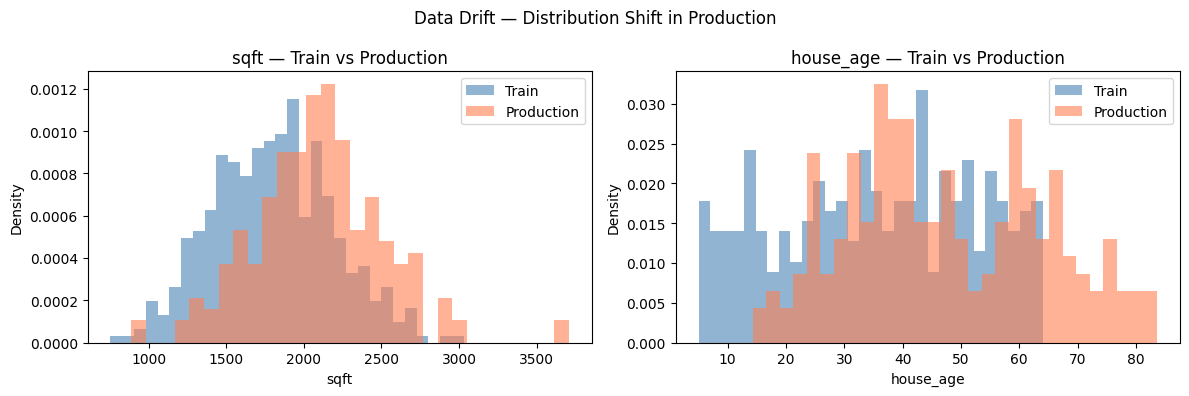

In [11]:
# Visualize sqft drift
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, ['sqft', 'house_age']):
    ax.hist(X_train[col], bins=30, alpha=0.6, color='steelblue', label='Train', density=True)
    ax.hist(production_data[col], bins=30, alpha=0.6, color='coral', label='Production', density=True)
    ax.set_title(f'{col} — Train vs Production')
    ax.set_xlabel(col)
    ax.set_ylabel('Density')
    ax.legend()

plt.suptitle('Data Drift — Distribution Shift in Production', fontsize=12)
plt.tight_layout()
plt.show()

---
## Section 5: What to Learn Next

This guide covered the core DS toolkit. To go deeper:

**Modeling depth**
- XGBoost / LightGBM — industry-standard gradient boosting
- Neural networks — PyTorch or TensorFlow for deep learning
- Time series models — ARIMA, Prophet, LSTM

**Statistics**
- Bayesian inference — posterior distributions, MCMC
- Causal inference — difference-in-differences, instrumental variables
- Survival analysis — time-to-event modeling

**Production & Engineering**
- MLflow / Weights & Biases — experiment tracking
- Feature stores — Feast, Tecton
- Model serving — FastAPI, BentoML, SageMaker
- Data pipelines — Airflow, dbt

**Practice**
- Kaggle competitions — structured feedback, diverse datasets
- Reproduce a paper — forces deep understanding
- Build an end-to-end project — data → model → deployment → monitoring